**Data Source:**  
Images were collected by author and are free for academic use  
visal rengan. (2026). dataset of bike, car, cat, dog. [Dataset]. Kaggle. https://doi.org/10.34740/KAGGLE/DSV/14807807

In [ ]:
from google.colab import drive
drive.mount('/content/drive')


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import os
os.chdir('/content/drive/My Drive/colab/CSC6502 - Computer Vision/cv_practical_work/csc6502-prac4-CHIPOMPO')
print(os.getcwd())


/content/drive/My Drive/colab/CSC6502 - Computer Vision/cv_practical_work/csc6502-prac4-CHIPOMPO


In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import datasets, transforms
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

Classes: ['class1', 'class2', 'class3', 'class4']


/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


Epoch 1: Train Acc 45.36%, Val Acc 50.00%
Epoch 2: Train Acc 63.21%, Val Acc 66.67%
Epoch 3: Train Acc 66.79%, Val Acc 68.33%
Epoch 4: Train Acc 73.21%, Val Acc 65.00%
Epoch 5: Train Acc 74.29%, Val Acc 73.33%
Epoch 6: Train Acc 76.43%, Val Acc 73.33%
Epoch 7: Train Acc 72.50%, Val Acc 65.00%
Epoch 8: Train Acc 80.00%, Val Acc 68.33%
Epoch 9: Train Acc 82.50%, Val Acc 70.00%
Epoch 10: Train Acc 83.93%, Val Acc 78.33%
Epoch 11: Train Acc 84.64%, Val Acc 73.33%
Epoch 12: Train Acc 85.71%, Val Acc 71.67%
Epoch 13: Train Acc 84.29%, Val Acc 70.00%
Epoch 14: Train Acc 89.64%, Val Acc 75.00%
Epoch 15: Train Acc 91.07%, Val Acc 71.67%


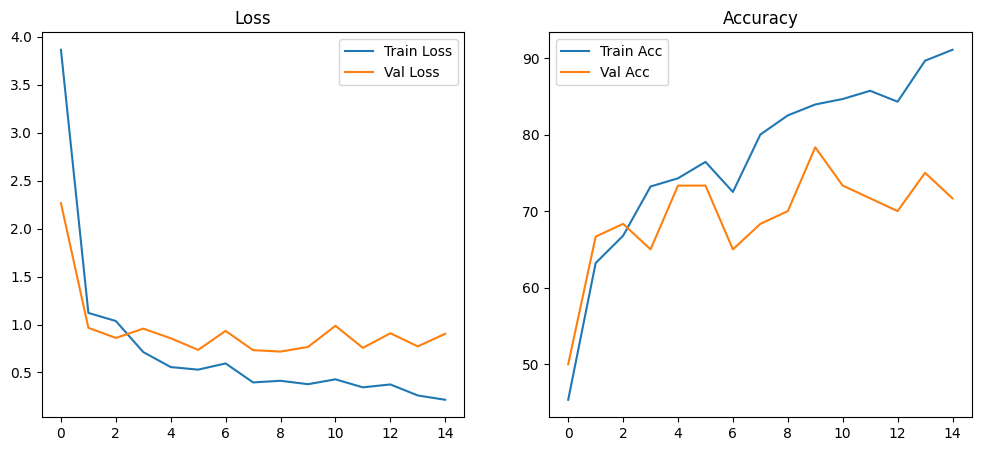

Final Test Accuracy: 0.7333333333333333


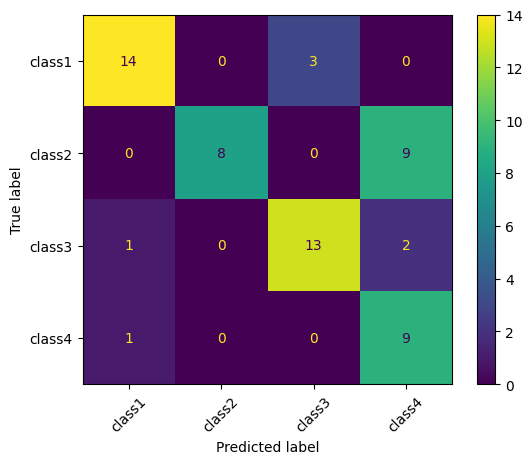

In [ ]:


##############################
# Define transforms
##############################
# Resize images to 128x128, apply augmentation (flip, rotation),
# convert to tensor, and normalize pixel values
transform = transforms.Compose([
    transforms.Resize((128,128)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),
    transforms.ToTensor(),
    transforms.Normalize((0.5,0.5,0.5), (0.5,0.5,0.5))
])

##############################
#Load dataset
##############################
# ImageFolder automatically assigns labels based on subfolder names
dataset = datasets.ImageFolder("dataset", transform=transform)

# Split dataset into train (70%), validation (15%), and test (15%)
total_size = len(dataset)
train_size = int(0.70 * total_size)
val_size = int(0.15 * total_size)
test_size = total_size - train_size - val_size

train_data, val_data, test_data = torch.utils.data.random_split(
    dataset,
    [train_size, val_size, test_size],
    generator=torch.Generator().manual_seed(42)
)

# Wrap datasets in DataLoader for batching
train_loader = DataLoader(train_data, batch_size=16, shuffle=True)
val_loader   = DataLoader(val_data, batch_size=16, shuffle=False)
test_loader  = DataLoader(test_data, batch_size=16, shuffle=False)

# Print class names (taken from folder names)
classes = dataset.classes
print("Classes:", classes)

##############################
# Define CNN model
##############################
class SmallCNN(nn.Module):
    def __init__(self):
        super(SmallCNN, self).__init__()
        # Feature extractor: 3 conv blocks
        self.features = nn.Sequential(
            nn.Conv2d(3, 32, 3, padding=1),   # Conv layer (input: 3 channels, output: 32)
            nn.BatchNorm2d(32),               # Normalize activations
            nn.ReLU(),                        # Non-linearity
            nn.MaxPool2d(2),                  # Downsample

            nn.Conv2d(32, 64, 3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(64, 128, 3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.MaxPool2d(2),
        )
        # Classifier head: flatten + fully connected layers
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(128*16*16, 128),        # Adjust depending on image size
            nn.ReLU(),
            nn.Linear(128, len(classes))      # Output = number of classes
        )

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x

net = SmallCNN()

##############################
# Loss & Optimizer
##############################
criterion = nn.CrossEntropyLoss()          # Suitable for multi-class classification
optimizer = optim.Adam(net.parameters(), lr=0.001)

##############################
# Training loop
##############################
train_losses, val_losses = [], []
train_accs, val_accs = [], []

for epoch in range(15):  # Train for 15 epochs
    net.train()          # Set model to training mode
    correct, total, running_loss = 0, 0, 0

    # Iterate over training batches
    for inputs, labels in train_loader:
        optimizer.zero_grad()              # Reset gradients
        outputs = net(inputs)              # Forward pass
        loss = criterion(outputs, labels)  # Compute loss
        loss.backward()                    # Backpropagation
        optimizer.step()                   # Update weights

        running_loss += loss.item()
        _, predicted = outputs.max(1)      # Get predicted class
        total += labels.size(0)
        correct += predicted.eq(labels).sum().item()

    train_losses.append(running_loss/len(train_loader))
    train_accs.append(100.*correct/total)

    # Validation step
    net.eval()
    val_loss, val_correct, val_total = 0, 0, 0
    with torch.no_grad():                  # Disable gradient computation
        for inputs, labels in val_loader:
            outputs = net(inputs)
            loss = criterion(outputs, labels)
            val_loss += loss.item()
            _, predicted = outputs.max(1)
            val_total += labels.size(0)
            val_correct += predicted.eq(labels).sum().item()

    val_losses.append(val_loss/len(val_loader))
    val_accs.append(100.*val_correct/val_total)

    print(f"Epoch {epoch+1}: Train Acc {train_accs[-1]:.2f}%, Val Acc {val_accs[-1]:.2f}%")

##############################
# Plot Loss & Accuracy
##############################
plt.figure(figsize=(12,5))
plt.subplot(1,2,1)
plt.plot(train_losses, label='Train Loss')
plt.plot(val_losses, label='Val Loss')
plt.legend(); plt.title("Loss")

plt.subplot(1,2,2)
plt.plot(train_accs, label='Train Acc')
plt.plot(val_accs, label='Val Acc')
plt.legend(); plt.title("Accuracy")
plt.show()

##############################
# Test evaluation
##############################
y_true, y_pred = [], []
net.eval()
with torch.no_grad():
    for inputs, labels in test_loader:
        outputs = net(inputs)
        _, predicted = outputs.max(1)
        y_true.extend(labels.numpy())
        y_pred.extend(predicted.numpy())

# Compute final test accuracy
acc = sum([p==t for p,t in zip(y_pred,y_true)])/len(y_true)
print("Final Test Accuracy:", acc)

# Confusion matrix
cm = confusion_matrix(y_true, y_pred)
ConfusionMatrixDisplay(cm, display_labels=classes).plot(xticks_rotation=45)
plt.show()



The model begins to overfit after around about 8 epochs, when training accuracy continues to improve but validation accuracy plateaus and validation loss fluctuates instead of improving.
The confusion matrix highlights specific class pairs that the model struggles to separate. The largest confusion occurs between class2 (cats) and class4 (dogs), with nearly half of class2 samples misclassified as class4. This suggests strong visual similarity between these categories, such as overlapping textures, shapes, or contexts. A secondary confusion appears between class1 (bikes) and class3(cars), where several class1 samples are predicted as class3.
These misclassifications make visual sense: the model relies on low‑level features like edges, colors, and textures. When two classes share those characteristics, the network finds it difficult to distinguish them, leading to systematic confusion.